# Chinese vs. English LLM prompts: pragmatic coding analysis

This notebook reproduces the quantitative analysis of the BA thesis *Linguistic Differences between Chinese and English Prompts for LLMs* (Tomsk State University, 2026) from the released coding sheet.

* `data/prompt_corpus_coded.csv`: 100 prompts (50 English from Reddit, 50 Chinese from Xiaohongshu), each coded on five dimensions:
  * AP1 speech act
  * AP2 directness
  * AP3 role setting
  * AP4 format constraint
  * AP5 step requirement
* `data/pilot_double_coding.csv`: 20 pilot prompts coded independently by two coders, used for inter-coder reliability.

In [1]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency, fisher_exact
import matplotlib.pyplot as plt

df = pd.read_csv("data/prompt_corpus_coded.csv")
pilot = pd.read_csv("data/pilot_double_coding.csv")

DIMS = {
    "AP1_speech_act": ["command", "request", "other"],
    "AP2_directness": ["direct", "indirect"],
    "AP3_role": ["yes", "no"],
    "AP4_format": ["yes", "no"],
    "AP5_steps": ["yes", "no"],
}
print(df.groupby("lang").size())

lang
EN    50
ZH    50
dtype: int64


## 1. Distribution of codes by language

In [2]:
rows = []
for dim, levels in DIMS.items():
    for lang in ["EN", "ZH"]:
        sub = df[df.lang == lang]
        for lv in levels:
            n = (sub[dim] == lv).sum()
            rows.append({"dimension": dim, "code": lv, "lang": lang, "n": n, "pct": round(100 * n / len(sub))})
dist = pd.DataFrame(rows).pivot_table(index=["dimension", "code"], columns="lang", values=["n", "pct"]).astype(int)
dist = dist.reindex([(d, l) for d, ls in DIMS.items() for l in ls])
print(dist.to_string())

                          n     pct    
lang                     EN  ZH  EN  ZH
dimension      code                    
AP1_speech_act command   30  15  60  30
               request    4  26   8  52
               other     16   9  32  18
AP2_directness direct    40  19  80  38
               indirect  10  31  20  62
AP3_role       yes       10  12  20  24
               no        40  38  80  76
AP4_format     yes        9  11  18  22
               no        41  39  82  78
AP5_steps      yes       11   7  22  14
               no        39  43  78  86


No prompt in the coding sheet was coded as *suggestion*, so AP1 is analysed with three categories.

## 2. Significance tests

* Each dimension gets a chi-square test of independence (language × code), with Cramér's V as the effect size (equal to φ for 2 × 2 tables).
* The 2 × 2 tables are also checked with Fisher's exact test.

In [3]:
def test(data, dim, levels):
    tab = np.array([[(data[data.lang == l][dim] == v).sum() for v in levels] for l in ["EN", "ZH"]])
    chi2, p, dof, exp = chi2_contingency(tab, correction=False)
    v = np.sqrt(chi2 / (tab.sum() * (min(tab.shape) - 1)))
    out = {"dimension": dim, "chi2": round(chi2, 2), "df": dof, "p": p, "effect_size": round(v, 2),
           "min_expected": round(exp.min(), 1)}
    if tab.shape == (2, 2):
        out["fisher_p"] = fisher_exact(tab)[1]
    return out

results = pd.DataFrame([test(df, d, l) for d, l in DIMS.items()])
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
print(results.to_string(index=False))

     dimension    chi2  df      p  effect_size  min_expected  fisher_p
AP1_speech_act 23.0900   2 0.0000       0.4800       12.5000       NaN
AP2_directness 18.2300   1 0.0000       0.4300       20.5000    0.0000
      AP3_role  0.2300   1 0.6292       0.0500       11.0000    0.8097
    AP4_format  0.2500   1 0.6171       0.0500       10.0000    0.8031
     AP5_steps  1.0800   1 0.2978       0.1000        9.0000    0.4356


### Sensitivity check: duplicate prompt

The English prompt *"Summarize the following using this structure: 1. Key Idea 2. Insights 3. Action Items"* appears twice (EN04 and EN28), with identical codes. The tests are re-run below without EN28.

In [4]:
dedup = df[df.id != "EN28"]
print(pd.DataFrame([test(dedup, d, l) for d, l in DIMS.items()])[["dimension", "chi2", "p", "effect_size"]].to_string(index=False))

     dimension    chi2      p  effect_size
AP1_speech_act 22.5400 0.0000       0.4800
AP2_directness 17.6400 0.0000       0.4200
      AP3_role  0.1800 0.6673       0.0400
    AP4_format  0.5100 0.4736       0.0700
     AP5_steps  0.7100 0.3980       0.0800


## 3. Inter-coder reliability on the 20 pilot prompts (Cohen's kappa)

Coder 2 left one AP3 code blank (ZH01), so AP3 is computed on 19 pairs.

In [5]:
def cohen_kappa(a, b):
    a, b = list(a), list(b)
    cats = sorted(set(a) | set(b))
    n = len(a)
    po = sum(x == y for x, y in zip(a, b)) / n
    pe = sum((a.count(c) / n) * (b.count(c) / n) for c in cats)
    return (po - pe) / (1 - pe)

rows = []
for d in ["AP1", "AP2", "AP3", "AP4", "AP5"]:
    pair = pilot[[d + "_coder1", d + "_coder2"]].dropna()   # one AP3 code was left blank by coder 2 (ZH01)
    rows.append({"dimension": d, "pairs": len(pair),
                 "agreement": f"{(pair.iloc[:, 0] == pair.iloc[:, 1]).sum()}/{len(pair)}",
                 "kappa": round(cohen_kappa(pair.iloc[:, 0], pair.iloc[:, 1]), 3)})
kappa = pd.DataFrame(rows)
print(kappa.to_string(index=False))
print("mean kappa:", round(kappa.kappa.mean(), 3))

dimension  pairs agreement  kappa
      AP1     20     16/20 0.6430
      AP2     20     17/20 0.6810
      AP3     19     18/19 0.7710
      AP4     20     17/20 0.6250
      AP5     20     18/20 0.6920
mean kappa: 0.682


## 4. Pragmatic profile of English and Chinese prompts

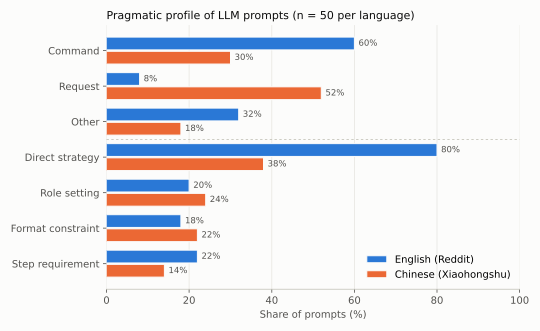

In [6]:
plt.rcParams.update({"svg.fonttype": "none", "font.family": "sans-serif", "font.size": 10, "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e"})
items = [("AP1_speech_act", "command", "Command"), ("AP1_speech_act", "request", "Request"),
         ("AP1_speech_act", "other", "Other"), ("AP2_directness", "direct", "Direct strategy"),
         ("AP3_role", "yes", "Role setting"), ("AP4_format", "yes", "Format constraint"),
         ("AP5_steps", "yes", "Step requirement")]
colors = {"EN": "#2a78d6", "ZH": "#eb6834"}
names = {"EN": "English (Reddit)", "ZH": "Chinese (Xiaohongshu)"}

fig, ax = plt.subplots(figsize=(7.5, 4.6), facecolor="#fcfcfb")
ax.set_facecolor("#fcfcfb")
y = np.arange(len(items))[::-1]
h = 0.36
for k, lang in enumerate(["EN", "ZH"]):
    sub = df[df.lang == lang]
    vals = [100 * (sub[d] == v).mean() for d, v, _ in items]
    bars = ax.barh(y + (h / 2 + 0.02) * (1 if k == 0 else -1), vals, height=h,
                   color=colors[lang], label=names[lang], edgecolor="#fcfcfb", linewidth=1)
    for b, v in zip(bars, vals):
        ax.text(v + 1, b.get_y() + b.get_height() / 2, f"{v:.0f}%", va="center", fontsize=8.5, color="#52514e")
ax.set_yticks(y, [lab for _, _, lab in items])
ax.set_xlim(0, 100)
ax.set_xlabel("Share of prompts (%)")
ax.xaxis.grid(True, color="#e7e6e1", linewidth=0.8)
ax.set_axisbelow(True)
for s in ["top", "right", "left"]:
    ax.spines[s].set_visible(False)
ax.axhline(3.5, color="#c3c2b7", linewidth=0.8, linestyle=(0, (3, 3)))
ax.legend(loc="lower right", frameon=False)
ax.set_title("Pragmatic profile of LLM prompts (n = 50 per language)", loc="left", fontsize=11, color="#0b0b0b")
plt.tight_layout()
plt.savefig("figures/pragmatic_profile.svg", facecolor="#fcfcfb")
plt.show()

## Summary

* **Speech acts and directness differ strongly by language.** English prompts are mostly direct commands, while Chinese prompts are mostly softened requests. Both differences are highly significant with medium-to-large effect sizes, and they remain so after removing the duplicate prompt.
* **Metapragmatic control does not differ.** Role setting, format constraints and step requirements occur at similar rates in both languages, and none of the differences is significant.
* **Note on figures.** All percentages here come from the released coding sheet and supersede those in the submitted thesis text. Two English prompts that were missing from the original sheet were coded afterwards following the coding manual (see `coding_note`).